In [5]:

# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Machine Learning algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, IsolationForest

# Handling imbalanced data
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

# Model evaluation
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

import warnings
warnings.filterwarnings('ignore')


In [6]:
# Load the dataset
df = pd.read_csv('/content/creditcard.csv')

# Display first five rows
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [7]:
# Check dataset dimensions
print("Dataset Shape:", df.shape)

# Check column information
df.info()

Dataset Shape: (284807, 31)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-n

In [8]:
# Statistical summary
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


In [9]:
# Check missing values in each column
print(df.isnull().sum().sum())

0


In [10]:
# Check duplicate rows
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 1081


In [11]:
# Count transactions in each class
print(df['Class'].value_counts())

# Calculate percentage distribution
print(df['Class'].value_counts(normalize=True) * 100)

Class
0    284315
1       492
Name: count, dtype: int64
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


In [12]:
# Remove exact duplicate rows
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)
print("\nClass distribution:")
print(df['Class'].value_counts())

Shape after removing duplicates: (283726, 31)

Class distribution:
Class
0    283253
1       473
Name: count, dtype: int64


In [13]:
# Separate features and target
X = df.drop('Class', axis=1)
y = df['Class']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (283726, 30)
Target shape: (283726,)


In [14]:
# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training data: (226980, 30)
Testing data: (56746, 30)

Training class distribution:
Class
0    226602
1       378
Name: count, dtype: int64

Testing class distribution:
Class
0    56651
1       95
Name: count, dtype: int64


In [15]:
# Initialize the scaler
scaler = StandardScaler()

# Fit on training data and transform both datasets
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)


Training data shape: (226980, 30)
Testing data shape: (56746, 30)


In [16]:
# Apply Random Undersampling
rus = RandomUnderSampler(random_state=42)

X_train_under, y_train_under = rus.fit_resample(
    X_train_scaled, y_train
)

print("Class distribution after undersampling:")
print(y_train_under.value_counts())

Class distribution after undersampling:
Class
0    378
1    378
Name: count, dtype: int64


In [17]:
# Apply SMOTE
smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_scaled, y_train
)

print("Class distribution after SMOTE:")
print(y_train_smote.value_counts())

Class distribution after SMOTE:
Class
0    226602
1    226602
Name: count, dtype: int64


In [18]:
# Train Logistic Regression on original data
lr_original = LogisticRegression(max_iter=1000)

lr_original.fit(X_train_scaled, y_train)

print("Logistic Regression training completed.")

Logistic Regression training completed.


In [19]:
# Train Logistic Regression on undersampled data
lr_under = LogisticRegression(max_iter=1000)

lr_under.fit(X_train_under, y_train_under)

print("Logistic Regression (Undersampling) training completed.")

Logistic Regression (Undersampling) training completed.


In [20]:
# Train Logistic Regression on SMOTE data
lr_smote = LogisticRegression(max_iter=1000)

lr_smote.fit(X_train_smote, y_train_smote)

print("Logistic Regression (SMOTE) training completed.")

Logistic Regression (SMOTE) training completed.


In [21]:
# Generate predictions
y_pred_original = lr_original.predict(X_test_scaled)
y_pred_under = lr_under.predict(X_test_scaled)
y_pred_smote = lr_smote.predict(X_test_scaled)

# Generate prediction probabilities for ROC-AUC
y_prob_original = lr_original.predict_proba(X_test_scaled)[:, 1]
y_prob_under = lr_under.predict_proba(X_test_scaled)[:, 1]
y_prob_smote = lr_smote.predict_proba(X_test_scaled)[:, 1]

print("Predictions generated successfully.")

Predictions generated successfully.


In [22]:
# Evaluate Logistic Regression models

results = pd.DataFrame({
    'Model': ['Original', 'Undersampling', 'SMOTE'],
    'Precision': [
        precision_score(y_test, y_pred_original),
        precision_score(y_test, y_pred_under),
        precision_score(y_test, y_pred_smote)
    ],
    'Recall': [
        recall_score(y_test, y_pred_original),
        recall_score(y_test, y_pred_under),
        recall_score(y_test, y_pred_smote)
    ],
    'F1-Score': [
        f1_score(y_test, y_pred_original),
        f1_score(y_test, y_pred_under),
        f1_score(y_test, y_pred_smote)
    ],
    'ROC-AUC': [
        roc_auc_score(y_test, y_prob_original),
        roc_auc_score(y_test, y_prob_under),
        roc_auc_score(y_test, y_prob_smote)
    ]
})

results

,Model,Precision,Recall,F1-Score,ROC-AUC
0,Original,0.846154,0.578947,0.687500,0.956047
1,Undersampling,0.050425,0.873684,0.095348,0.957108
2,SMOTE,0.053035,0.873684,0.100000,0.962618


In [23]:
# Confusion matrices for Logistic Regression
print("Original Data:")
print(confusion_matrix(y_test, y_pred_original))

print("\nUndersampling:")
print(confusion_matrix(y_test, y_pred_under))

print("\nSMOTE:")
print(confusion_matrix(y_test, y_pred_smote))


Original Data:
[[56641    10]
 [   40    55]]

Undersampling:
[[55088  1563]
 [   12    83]]

SMOTE:
[[55169  1482]
 [   12    83]]


In [24]:
# Train Decision Tree
dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train, y_train)

print("Decision Tree training completed.")

Decision Tree training completed.


In [25]:
# Generate Decision Tree predictions
y_pred_dt = dt_model.predict(X_test)

# Generate fraud probabilities
y_prob_dt = dt_model.predict_proba(X_test)[:, 1]

print("Decision Tree predictions generated.")

Decision Tree predictions generated.


In [26]:
# Evaluate Decision Tree
print("Precision:", precision_score(y_test, y_pred_dt))
print("Recall:", recall_score(y_test, y_pred_dt))
print("F1-Score:", f1_score(y_test, y_pred_dt))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_dt))

Precision: 0.7204301075268817
Recall: 0.7052631578947368
F1-Score: 0.7127659574468085
ROC-AUC: 0.8524021037395169


In [27]:
# Train Random Forest
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest training completed.")

Random Forest training completed.


In [28]:
# Generate Random Forest predictions
y_pred_rf = rf_model.predict(X_test)

# Generate fraud probabilities
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest predictions generated.")

Random Forest predictions generated.


In [29]:
# Evaluate Random Forest
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1-Score:", f1_score(y_test, y_pred_rf))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_rf))

Precision: 0.971830985915493
Recall: 0.7263157894736842
F1-Score: 0.8313253012048193
ROC-AUC: 0.9239442050077622


In [30]:
# Train Isolation Forest
iso_model = IsolationForest(
    n_estimators=100,
    contamination=0.0017,
    random_state=42,
    n_jobs=-1
)

iso_model.fit(X_train)

print("Isolation Forest training completed.")

Isolation Forest training completed.


In [31]:
# Generate Isolation Forest predictions
iso_predictions = iso_model.predict(X_test)

# Convert predictions to dataset labels
y_pred_iso = np.where(iso_predictions == -1, 1, 0)

print("Isolation Forest predictions generated.")

Isolation Forest predictions generated.


In [32]:
# Evaluate Isolation Forest
print("Precision:", precision_score(y_test, y_pred_iso))
print("Recall:", recall_score(y_test, y_pred_iso))
print("F1-Score:", f1_score(y_test, y_pred_iso))
print("ROC-AUC:", roc_auc_score(y_test, -iso_model.decision_function(X_test)))

Precision: 0.18811881188118812
Recall: 0.2
F1-Score: 0.19387755102040816
ROC-AUC: 0.9299849772708059


In [33]:
# Train Random Forest using SMOTE
rf_smote = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_smote.fit(X_train_smote, y_train_smote)

print("Random Forest with SMOTE training completed.")

Random Forest with SMOTE training completed.


In [34]:
y_pred_rf_smote = rf_smote.predict(X_test_scaled)
y_prob_rf_smote = rf_smote.predict_proba(X_test_scaled)[:, 1]

print("Precision:", precision_score(y_test, y_pred_rf_smote))
print("Recall:", recall_score(y_test, y_pred_rf_smote))
print("F1-Score:", f1_score(y_test, y_pred_rf_smote))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_rf_smote))

Precision: 0.9125
Recall: 0.7684210526315789
F1-Score: 0.8342857142857143
ROC-AUC: 0.9694220104815354


In [35]:
rf_under = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_under.fit(X_train_under, y_train_under)

print("Random Forest with undersampling training completed.")

Random Forest with undersampling training completed.


In [36]:
y_pred_rf_under = rf_under.predict(X_test_scaled)
y_prob_rf_under = rf_under.predict_proba(X_test_scaled)[:, 1]

In [37]:
print("Precision:", precision_score(y_test, y_pred_rf_under))
print("Recall:", recall_score(y_test, y_pred_rf_under))
print("F1-Score:", f1_score(y_test, y_pred_rf_under))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_rf_under))

Precision: 0.08478038815117467
Recall: 0.8736842105263158
F1-Score: 0.15456238361266295
ROC-AUC: 0.9766969320000854


In [38]:
final_results = pd.DataFrame({
    'Model': [
        'Logistic Regression - Original',
        'Logistic Regression - Undersampling',
        'Logistic Regression - SMOTE',
        'Decision Tree - Original',
        'Random Forest - Original',
        'Random Forest - SMOTE',
        'Random Forest - Undersampling',
        'Isolation Forest - Original'
    ],
    'Precision': [
        0.846154, 0.050425, 0.053035,
        0.720430, 0.971831, 0.9125, 0.084780, 0.188119
    ],
    'Recall': [
        0.578947, 0.873684, 0.873684,
        0.705263, 0.726316, 0.768421, 0.873684, 0.200000
    ],
    'F1-Score': [
        0.687500, 0.095348, 0.100000,
        0.712766, 0.831325, 0.834286, 0.154562, 0.193878
    ],
    'ROC-AUC': [
        0.956047, 0.957108, 0.962618,
        0.852402, 0.923944, 0.969422, 0.976697, 0.929985
    ]
})

final_results

,Model,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression - Original,0.846154,0.578947,0.687500,0.956047
1,Logistic Regression - Undersampling,0.050425,0.873684,0.095348,0.957108
2,Logistic Regression - SMOTE,0.053035,0.873684,0.100000,0.962618
3,Decision Tree - Original,0.720430,0.705263,0.712766,0.852402
4,Random Forest - Original,0.971831,0.726316,0.831325,0.923944
5,Random Forest - SMOTE,0.912500,0.768421,0.834286,0.969422
6,Random Forest - Undersampling,0.084780,0.873684,0.154562,0.976697
7,Isolation Forest - Original,0.188119,0.200000,0.193878,0.929985


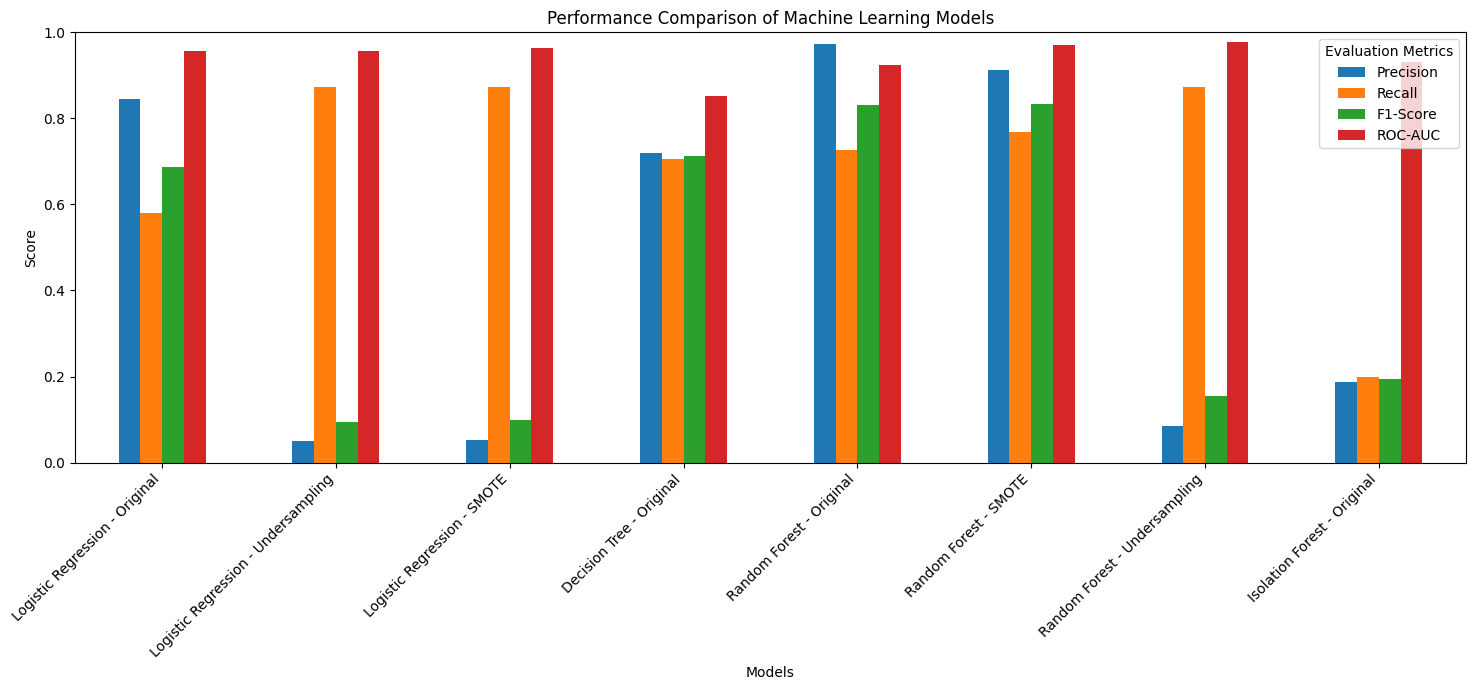

In [39]:
metrics = ['Precision', 'Recall', 'F1-Score', 'ROC-AUC']

final_results.set_index('Model')[metrics].plot(
    kind='bar',
    figsize=(15, 7)
)

plt.title('Performance Comparison of Machine Learning Models')
plt.ylabel('Score')
plt.xlabel('Models')
plt.xticks(rotation=45, ha='right')
plt.ylim(0, 1)
plt.legend(title='Evaluation Metrics')
plt.tight_layout()
plt.show()

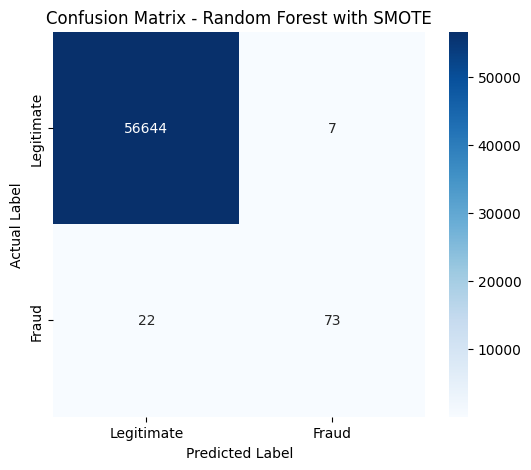

In [40]:
cm = confusion_matrix(y_test, y_pred_rf_smote)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Legitimate', 'Fraud'],
    yticklabels=['Legitimate', 'Fraud']
)

plt.title('Confusion Matrix - Random Forest with SMOTE')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.show()

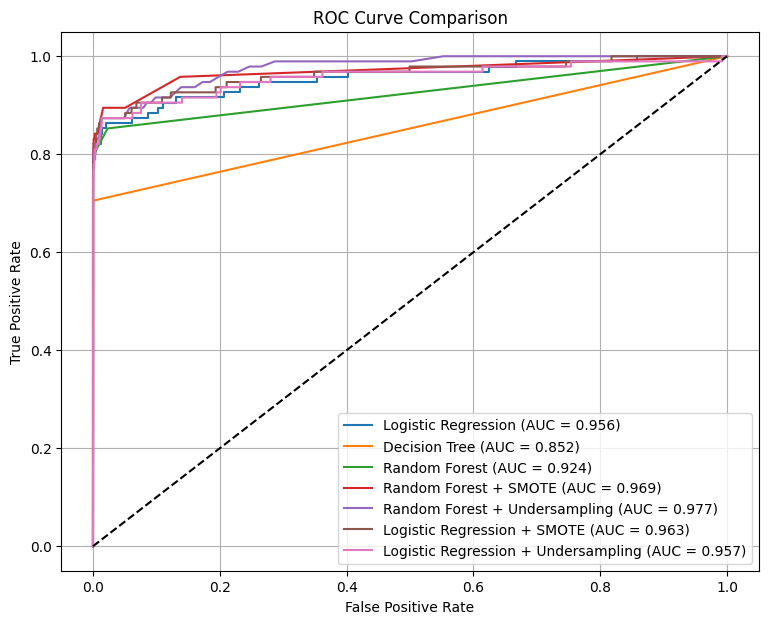

In [41]:
from sklearn.metrics import roc_curve

models = {
    'Logistic Regression': y_prob_original,
    'Decision Tree': y_prob_dt,
    'Random Forest': y_prob_rf,
    'Random Forest + SMOTE': y_prob_rf_smote,
    'Random Forest + Undersampling': y_prob_rf_under,
    'Logistic Regression + SMOTE': y_prob_smote,
    'Logistic Regression + Undersampling': y_prob_under
}

plt.figure(figsize=(9, 7))

for name, probabilities in models.items():
    fpr, tpr, thresholds = roc_curve(y_test, probabilities)
    auc = roc_auc_score(y_test, probabilities)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})')

plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend(loc='lower right')
plt.grid()
plt.show()

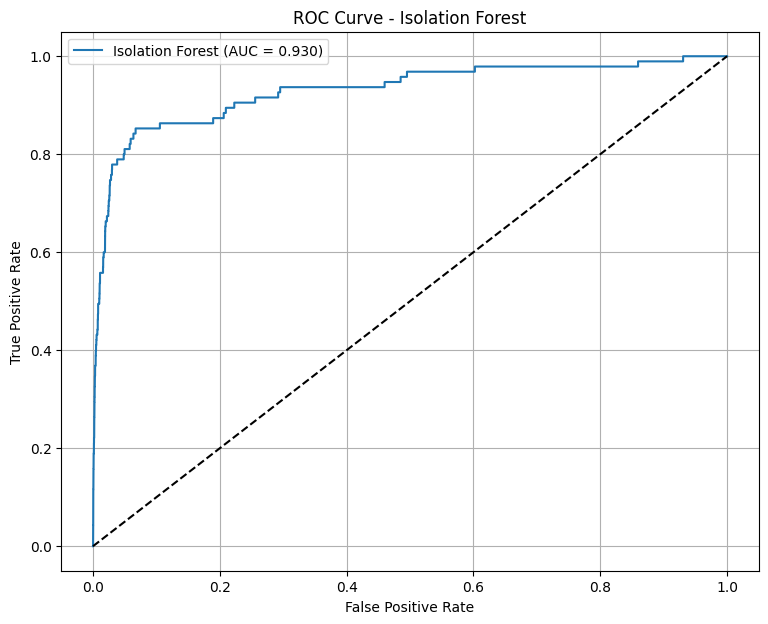

In [42]:
iso_scores = -iso_model.decision_function(X_test)

fpr_iso, tpr_iso, thresholds_iso = roc_curve(y_test, iso_scores)
auc_iso = roc_auc_score(y_test, iso_scores)

plt.figure(figsize=(9, 7))

plt.plot(
    fpr_iso,
    tpr_iso,
    label=f'Isolation Forest (AUC = {auc_iso:.3f})'
)

plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Isolation Forest')
plt.legend()
plt.grid()
plt.show()

Sample predictions and demonstrations


In [43]:
fraud_indices = y_test[y_test == 1].sample(
    n=3, random_state=42
).index

legitimate_indices = y_test[y_test == 0].sample(
    n=2, random_state=42
).index

sample_indices = fraud_indices.append(legitimate_indices)

X_sample = X_test.loc[sample_indices]
y_actual = y_test.loc[sample_indices]

In [44]:
X_sample_scaled = scaler.transform(X_sample)

y_sample_pred = rf_smote.predict(X_sample_scaled)

In [45]:
sample_results = X_sample.copy()

sample_results['Actual Class'] = y_actual
sample_results['Predicted Class'] = y_sample_pred

sample_results['Actual Class'] = sample_results['Actual Class'].map({
    0: 'Legitimate',
    1: 'Fraud'
})

sample_results['Predicted Class'] = sample_results['Predicted Class'].map({
    0: 'Legitimate',
    1: 'Fraud'
})

display(sample_results)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V22,V23,V24,V25,V26,V27,V28,Amount,Actual Class,Predicted Class
56703,47545.0,1.176716,0.557091,-0.490800,0.756424,0.249192,-0.781871,0.228750,-0.040840,-0.432111,...,-0.128168,-0.040176,0.110040,0.437891,0.368809,-0.018287,0.031173,0.76,Fraud,Legitimate
229712,146022.0,0.908637,2.849024,-5.647343,6.009415,0.216656,-2.397014,-1.819308,0.338527,-2.819883,...,-0.397435,-0.080006,-0.168597,0.465058,0.210510,0.648705,0.360224,1.18,Fraud,Fraud
163586,116067.0,0.949241,1.333519,-4.855402,1.835006,-1.053245,-2.562826,-2.286986,0.260906,-0.895366,...,-0.854627,0.101177,-0.281497,0.024444,-0.107944,0.625289,0.315677,65.00,Fraud,Fraud
172138,120975.0,-0.638968,0.742082,0.902562,1.115908,0.076009,0.415351,-0.003078,0.688597,-0.164379,...,-0.874359,0.177827,-0.472989,-0.799794,-1.001761,0.137700,0.104794,21.20,Legitimate,Legitimate
277900,167925.0,-0.779481,1.647737,-2.938721,-1.166668,2.159616,4.953595,-3.737302,-7.827428,-0.736396,...,1.872172,0.590855,0.677397,0.029891,-0.148101,0.197307,0.440745,1.00,Legitimate,Legitimate
